# 03 – Phân cụm điểm nóng (hotspot) F&B

Mục tiêu: tìm các **khu tập trung cửa hàng** (hotspot) và mô tả đặc trưng của chúng. Sau đó phân cụm **phường** theo cơ cấu loại hình.

So sánh ba thuật toán:
| Thuật toán | Đầu vào | Ghi chú |
|---|---|---|
| K-Means | tọa độ UTM 49N (mét) | K-Means dùng khoảng cách Euclid, nên **không** dùng trực tiếp độ (1° kinh ≠ 1° vĩ về mét) |
| DBSCAN | (lat, lon) radian, `metric="haversine"`, `algorithm="ball_tree"` | `eps = mét / 6.371.000` |
| HDBSCAN | tọa độ UTM (mét) | `sklearn.cluster.HDBSCAN` (sklearn ≥ 1.3) |

Ở phạm vi một quận (vài km), khoảng cách Euclid trên UTM và khoảng cách haversine chênh lệch không đáng kể (< 0,1%). Vì vậy Silhouette và Davies–Bouldin của cả ba thuật toán đều tính trên UTM (mét) để so sánh được với nhau.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium

from src import cleaning as cl, geo, features as ft, viz

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
viz.set_style()
PROC = ROOT / "data" / "processed"
TABLES = viz.TABLE_DIR

from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.metrics import silhouette_score
from src import clustering as cu

df = pd.read_csv(PROC / "stores_clean.csv")
df["type_group"] = [ft.primary_group(t, c) for t, c in zip(df["product_types"], df["category"])]
df["street"] = df["address"].map(cl.street_of)
xy = geo.to_utm(df)
print(df.shape)

(3208, 49)


## 1. K-Means trên tọa độ UTM: chọn k bằng Elbow và Silhouette

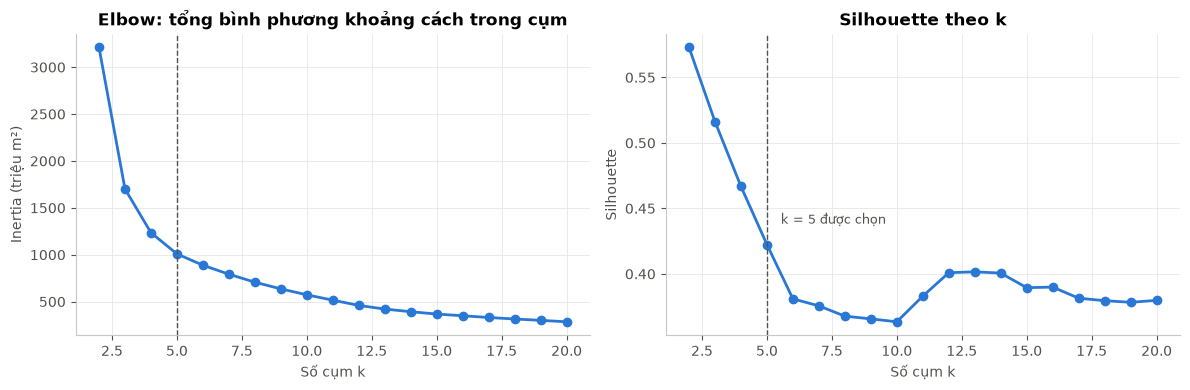

k,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
inertia,3.210659e+09,1.701313e+09,1.235004e+09,1.008748e+09,8.882081e+08,7.921428e+08,7.074990e+08,6.357015e+08,5.729157e+08,5.152664e+08,4.599310e+08,4.206190e+08,3.924695e+08,3.674544e+08,3.493967e+08,3.309122e+08,3.148791e+08,3.003346e+08,2.852004e+08
silhouette,5.730000e-01,5.160000e-01,4.670000e-01,4.220000e-01,3.810000e-01,3.760000e-01,3.680000e-01,3.660000e-01,3.630000e-01,3.830000e-01,4.010000e-01,4.020000e-01,4.010000e-01,3.890000e-01,3.900000e-01,3.810000e-01,3.800000e-01,3.780000e-01,3.800000e-01
davies_bouldin,5.900000e-01,6.440000e-01,7.350000e-01,8.150000e-01,9.020000e-01,9.270000e-01,8.940000e-01,8.860000e-01,9.100000e-01,8.270000e-01,7.950000e-01,7.640000e-01,7.700000e-01,7.860000e-01,7.770000e-01,7.840000e-01,7.910000e-01,8.220000e-01,8.130000e-01


In [2]:
km_scan = cu.kmeans_scan(xy, range(2, 21))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(km_scan["k"], km_scan["inertia"] / 1e6, "o-", color=viz.PALETTE[0], lw=2, ms=6)
axes[0].set_title("Elbow: tổng bình phương khoảng cách trong cụm"); axes[0].set_xlabel("Số cụm k")
axes[0].set_ylabel("Inertia (triệu m²)")
axes[1].plot(km_scan["k"], km_scan["silhouette"], "o-", color=viz.PALETTE[0], lw=2, ms=6)
axes[1].set_title("Silhouette theo k"); axes[1].set_xlabel("Số cụm k"); axes[1].set_ylabel("Silhouette")
K_KMEANS = int(km_scan.loc[km_scan["k"] >= 5].sort_values("silhouette", ascending=False).iloc[0]["k"])
for ax in axes:
    ax.axvline(K_KMEANS, ls="--", color=viz.TEXT_2, lw=1)
axes[1].annotate(f"k = {K_KMEANS} được chọn", (K_KMEANS, km_scan.set_index("k").loc[K_KMEANS, "silhouette"]),
                 xytext=(10, 15), textcoords="offset points", fontsize=9, color=viz.TEXT_2)
fig.tight_layout(); viz.save_fig(fig, "03_kmeans_elbow_silhouette"); plt.show()
km_scan.round(3).set_index("k").T

**Căn cứ chọn k:**
- Silhouette cao nhất ở **k = 2**: K-Means tách quận thành cực Bắc và cực Nam, đúng như bản đồ mật độ ở notebook 02. Tuy nhiên mức chia này quá thô để gọi là "điểm nóng".
- Đường Elbow giảm mạnh tới khoảng k = 4–5 rồi thoải dần, không có khuỷu sắc (dữ liệu phân bố liên tục).
- Ta yêu cầu tối thiểu **k ≥ 5** để có mức chi tiết cỡ "khu vực" và chọn k có **Silhouette cao nhất trong miền đó**. Kết quả là k = 5, cũng trùng với vùng khuỷu của Elbow.
  Silhouette có một cực đại phụ ở k = 12–13 (≈ 0,40), nhưng vẫn thấp hơn ở k = 5 (0,42).
- Hạn chế của K-Means: thuật toán **bắt buộc gán mọi cửa hàng vào một cụm**, kể cả cửa hàng lẻ loi, và giả định cụm có dạng cầu. Nó chỉ *chia vùng* chứ không *phát hiện điểm nóng*.

In [3]:
df["km_label"] = cu.relabel_by_size(cu.KMeans(n_clusters=K_KMEANS, n_init=10, random_state=RANDOM_STATE).fit_predict(xy))
print(df["km_label"].value_counts().sort_index().to_string())

km_label
0    790
1    685
2    665
3    660
4    408


## 2. DBSCAN (haversine): chọn eps bằng k-distance plot

Với mỗi cửa hàng, tính khoảng cách tới láng giềng thứ *k* (k = min_samples). Nếu sắp xếp các khoảng cách này tăng dần, điểm "khuỷu" của đường cong là gợi ý cho eps.

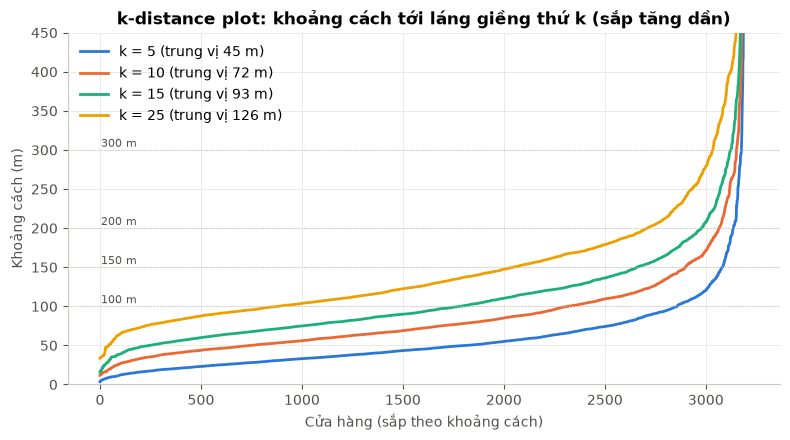

k= 5: p50=45 m, p75=70 m, p90=104 m
k=10: p50=72 m, p75=104 m, p90=147 m


k=15: p50=93 m, p75=130 m, p90=182 m
k=25: p50=126 m, p75=171 m, p90=234 m


In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, k in enumerate([5, 10, 15, 25]):
    kd = cu.k_distance(df, k)
    ax.plot(np.arange(len(kd)), kd, lw=2, color=viz.PALETTE[i], label=f"k = {k} (trung vị {np.median(kd):.0f} m)")
for e in (100, 150, 200, 300):
    ax.axhline(e, color="#c9c8c2", lw=0.8, ls=":")
    ax.text(5, e + 4, f"{e} m", fontsize=8, color=viz.TEXT_2)
ax.set_ylim(0, 450)
ax.set_title("k-distance plot: khoảng cách tới láng giềng thứ k (sắp tăng dần)")
ax.set_xlabel("Cửa hàng (sắp theo khoảng cách)"); ax.set_ylabel("Khoảng cách (m)")
ax.legend(loc="upper left")
fig.tight_layout(); viz.save_fig(fig, "03_k_distance"); plt.show()
for k in (5, 10, 15, 25):
    kd = cu.k_distance(df, k)
    print(f"k={k:>2}: p50={np.percentile(kd, 50):.0f} m, p75={np.percentile(kd, 75):.0f} m, p90={np.percentile(kd, 90):.0f} m")

Đường k-distance tăng **từ từ, không có khuỷu sắc**. Lý do là cửa hàng phủ liên tục trên toàn quận. Vì vậy ta quét lưới tham số và xem cấu trúc cụm thay đổi thế nào:
- eps ∈ {100, 150, 200, 250, 300} m × min_samples ∈ {5, 10, 15} (theo đề bài)
- mở rộng min_samples ∈ {20, 25, 30} và eps ∈ {60, 80, 120} m

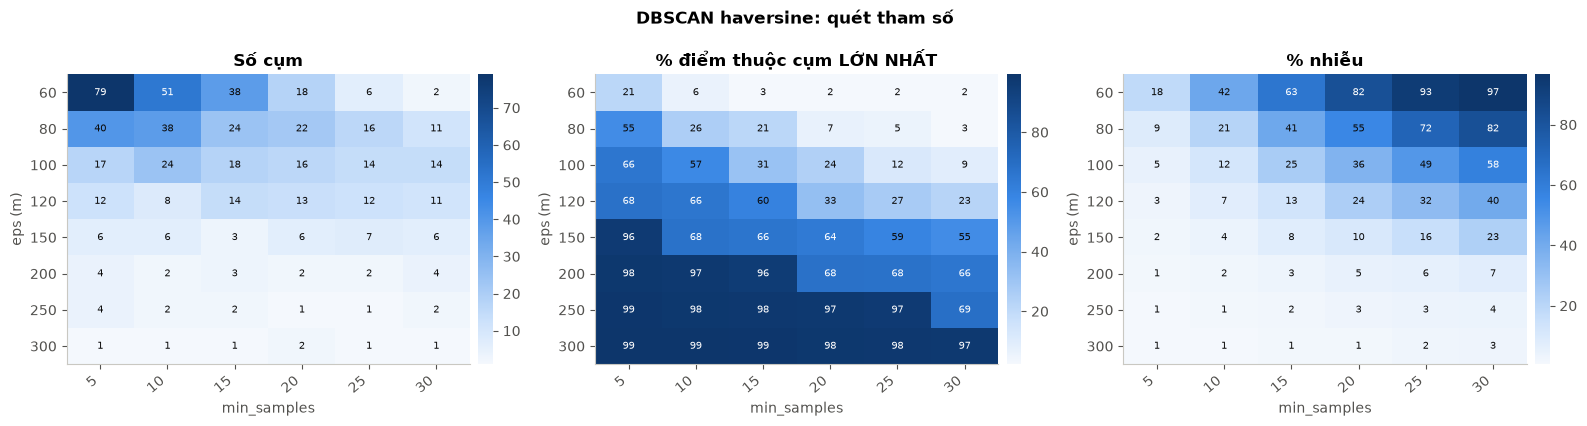

,eps_m,min_samples,n_clusters,noise_pct,largest_cluster_pct,silhouette,davies_bouldin
12,100,5,17,4.894,65.617,-0.243,0.739
13,100,10,24,11.845,56.702,-0.263,0.829
14,100,15,18,24.906,31.172,0.018,0.687
16,100,25,14,48.628,11.908,0.438,0.606
24,150,5,6,1.933,96.446,-0.389,0.900
25,150,10,6,3.959,67.862,0.059,0.580
26,150,15,3,7.668,66.272,0.496,0.478
28,150,25,7,15.804,58.853,0.063,0.679
30,200,5,4,1.216,98.036,-0.334,0.832
31,200,10,2,2.120,97.350,0.230,0.534


In [5]:
rows = []
for eps in (60, 80, 100, 120, 150, 200, 250, 300):
    for ms in (5, 10, 15, 20, 25, 30):
        lab = cu.dbscan_haversine(df, eps, ms)
        r = cu.cluster_metrics(xy, lab); r.update(eps_m=eps, min_samples=ms)
        rows.append(r)
db_scan = pd.DataFrame(rows)[["eps_m", "min_samples", "n_clusters", "noise_pct", "largest_cluster_pct",
                              "silhouette", "davies_bouldin"]]
db_scan.to_csv(TABLES / "03_dbscan_param_scan.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, col, title, fmt in [(axes[0], "n_clusters", "Số cụm", ".0f"),
                            (axes[1], "largest_cluster_pct", "% điểm thuộc cụm LỚN NHẤT", ".0f"),
                            (axes[2], "noise_pct", "% nhiễu", ".0f")]:
    piv = db_scan.pivot(index="eps_m", columns="min_samples", values=col)
    viz.heatmap(piv, title, "min_samples", "eps (m)", fmt=fmt, ax=ax)
fig.suptitle("DBSCAN haversine: quét tham số", fontweight="bold")
fig.tight_layout(); viz.save_fig(fig, "03_dbscan_param_scan"); plt.show()
db_scan[db_scan["eps_m"].isin([100, 150, 200, 300]) & db_scan["min_samples"].isin([5, 10, 15, 25])].round(3)

**Căn cứ chọn tham số DBSCAN:**
- Với **eps ≥ 150 m** và min_samples trong khoảng 5–15, DBSCAN rơi vào hiện tượng **nối chuỗi (chaining)**. Mật độ quán đủ dày để các vùng lõi nối liền nhau, nên một cụm nuốt 66–99% số cửa hàng. Kết quả "cả quận là một hotspot" vô nghĩa.
  Từ khoảng 300 m trở lên chỉ còn 1 cụm.
- Muốn tách được điểm nóng thì phải tăng ngưỡng mật độ. Ta chọn **eps = 100 m, min_samples = 25** với ý nghĩa: *một cửa hàng là lõi của hotspot nếu trong bán kính 100 m quanh nó có ít nhất 25 cửa hàng*, tương đương khoảng 8 cửa hàng/ha. Lý do chọn:
  - Bán kính 100 m tương đương khoảng 1–2 phút đi bộ, là quy mô "cụm quán" có ý nghĩa kinh doanh.
  - Cụm lớn nhất chỉ chiếm khoảng 12% số điểm, không còn nối chuỗi. Số cụm (14) đủ ít để diễn giải từng cụm.
  - Silhouette ≈ 0,44, cao hơn rõ rệt so với các cấu hình eps 100 m / ms ≤ 20.
  - eps 100 m nằm trong khoảng 100–300 m mà đề bài gợi ý. Chỉ min_samples phải nâng lên 25 vì mật độ thực tế cao.
- Khoảng 49% điểm là **nhiễu**. Ở đây nhiễu nghĩa là *không nằm trong hotspot*, không phải dữ liệu lỗi.
- Lưu ý: Silhouette và DBI của DBSCAN/HDBSCAN chỉ tính trên điểm không nhiễu, nên thường **thiên lạc quan** so với K-Means (vốn phải gán cả những điểm khó). Khi so sánh cần đọc kèm % nhiễu.

In [6]:
EPS_M, MIN_SAMPLES = 100, 25
df["dbscan_label"] = cu.relabel_by_size(cu.dbscan_haversine(df, EPS_M, MIN_SAMPLES))
df["is_hotspot"] = df["dbscan_label"] != -1
print(f"DBSCAN eps={EPS_M} m, min_samples={MIN_SAMPLES}: {df['dbscan_label'].max() + 1} hotspot, "
      f"{df['is_hotspot'].mean():.1%} cửa hàng nằm trong hotspot")
print(df.loc[df["is_hotspot"], "dbscan_label"].value_counts().sort_index().to_string())

DBSCAN eps=100 m, min_samples=25: 14 hotspot, 51.4% cửa hàng nằm trong hotspot
dbscan_label
0     382
1     299
2     198
3     142
4     118
5     111
6      98
7      66
8      58
9      45
10     38
11     38
12     30
13     25


## 3. HDBSCAN

HDBSCAN không cần chọn eps. Thuật toán xây cây phân cấp theo mật độ rồi chọn cụm ổn định.
- Với cách chọn mặc định `cluster_selection_method="eom"`, HDBSCAN cũng gộp phần lớn quận thành một cụm khổng lồ, giống như DBSCAN có eps lớn.
- Cách chọn `"leaf"` lấy các nút lá của cây, tức các lõi dày đặc nhất, nên phù hợp với mục tiêu tìm hotspot.

In [7]:
rows = []
for mcs, ms, meth in [(15, 10, "eom"), (30, 15, "eom"), (15, 10, "leaf"), (20, 15, "leaf"), (30, 15, "leaf"), (50, 20, "leaf")]:
    lab = cu.HDBSCAN(min_cluster_size=mcs, min_samples=ms, cluster_selection_method=meth, copy=True).fit_predict(xy)
    r = cu.cluster_metrics(xy, lab); r.update(min_cluster_size=mcs, min_samples=ms, method=meth)
    rows.append(r)
hdb_scan = pd.DataFrame(rows)[["method", "min_cluster_size", "min_samples", "n_clusters", "noise_pct",
                               "largest_cluster_pct", "silhouette", "davies_bouldin"]]
hdb_scan.round(3)

,method,min_cluster_size,min_samples,n_clusters,noise_pct,largest_cluster_pct,silhouette,davies_bouldin
0,eom,15,10,15,16.771,67.238,0.225,0.520
1,eom,30,15,4,11.814,66.365,0.409,0.520
2,leaf,15,10,50,50.125,2.525,0.560,0.574
3,leaf,20,15,29,58.074,4.925,0.561,0.512
4,leaf,30,15,21,56.359,5.673,0.539,0.559
5,leaf,50,20,14,62.999,5.019,0.574,0.540


In [8]:
HDB_MCS, HDB_MS = 30, 15
df["hdbscan_label"] = cu.relabel_by_size(
    cu.HDBSCAN(min_cluster_size=HDB_MCS, min_samples=HDB_MS, cluster_selection_method="leaf", copy=True).fit_predict(xy))
print(f"HDBSCAN (leaf, min_cluster_size={HDB_MCS}, min_samples={HDB_MS}): {df['hdbscan_label'].max() + 1} cụm, "
      f"nhiễu {(df['hdbscan_label'] == -1).mean():.1%}")
# Mức độ trùng khớp giữa hotspot của DBSCAN và HDBSCAN
from sklearn.metrics import adjusted_rand_score
both = (df["dbscan_label"] != -1) | (df["hdbscan_label"] != -1)
agree_hot = ((df["dbscan_label"] != -1) == (df["hdbscan_label"] != -1)).mean()
print(f"Tỉ lệ cửa hàng được 2 thuật toán đánh giá giống nhau (hotspot / không): {agree_hot:.1%}")
print(f"ARI giữa nhãn DBSCAN và HDBSCAN: {adjusted_rand_score(df['dbscan_label'], df['hdbscan_label']):.3f}")

HDBSCAN (leaf, min_cluster_size=30, min_samples=15): 21 cụm, nhiễu 56.4%
Tỉ lệ cửa hàng được 2 thuật toán đánh giá giống nhau (hotspot / không): 73.0%
ARI giữa nhãn DBSCAN và HDBSCAN: 0.376


## 4. So sánh ba thuật toán

In [9]:
comp = pd.DataFrame({
    f"K-Means (k={K_KMEANS})": cu.cluster_metrics(xy, df["km_label"].to_numpy()),
    f"DBSCAN (eps={EPS_M}m, ms={MIN_SAMPLES})": cu.cluster_metrics(xy, df["dbscan_label"].to_numpy()),
    f"HDBSCAN (leaf, mcs={HDB_MCS})": cu.cluster_metrics(xy, df["hdbscan_label"].to_numpy()),
}).T
comp.columns = ["Số cụm", "% nhiễu", "Silhouette", "Davies–Bouldin", "% điểm ở cụm lớn nhất"]
comp.to_csv(TABLES / "03_clustering_comparison.csv", encoding="utf-8-sig")
comp.round(3)

,Số cụm,% nhiễu,Silhouette,Davies–Bouldin,% điểm ở cụm lớn nhất
K-Means (k=5),5.0,0.000,0.422,0.815,24.626
"DBSCAN (eps=100m, ms=25)",14.0,48.628,0.438,0.606,11.908
"HDBSCAN (leaf, mcs=30)",21.0,56.359,0.539,0.559,5.673


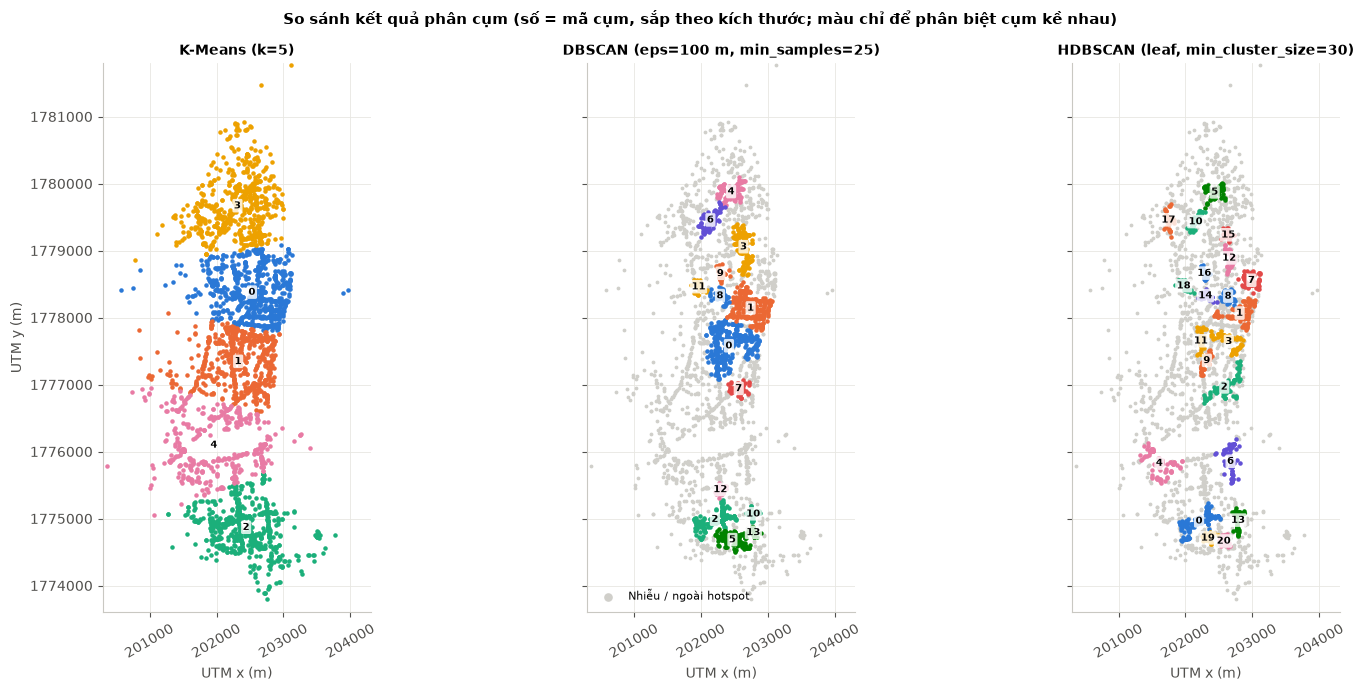

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 7), sharey=True)
for ax, col, title in [(axes[0], "km_label", f"K-Means (k={K_KMEANS})"),
                       (axes[1], "dbscan_label", f"DBSCAN (eps={EPS_M} m, min_samples={MIN_SAMPLES})"),
                       (axes[2], "hdbscan_label", f"HDBSCAN (leaf, min_cluster_size={HDB_MCS})")]:
    lab = df[col].to_numpy()
    noise = lab == -1
    ax.scatter(xy[noise, 0], xy[noise, 1], s=3, color="#d0cfca", label="Nhiễu / ngoài hotspot")
    for c in np.unique(lab[~noise]):
        m = lab == c
        ax.scatter(xy[m, 0], xy[m, 1], s=5, color=viz.PALETTE[c % len(viz.PALETTE)])
        cx, cy = xy[m].mean(axis=0)
        ax.text(cx, cy, str(c), fontsize=7.5, fontweight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10)
    ax.set_xlim(200300, 204300); ax.set_ylim(1773600, 1781800)
    ax.set_xlabel("UTM x (m)"); ax.tick_params(axis="x", rotation=30)
    ax.ticklabel_format(useOffset=False, style="plain")
axes[0].set_ylabel("UTM y (m)")
axes[1].legend(loc="lower left", fontsize=8, markerscale=3)
fig.suptitle("So sánh kết quả phân cụm (số = mã cụm, sắp theo kích thước; màu chỉ để phân biệt cụm kề nhau)",
             fontweight="bold", fontsize=11)
fig.tight_layout(); viz.save_fig(fig, "03_clustering_comparison_map"); plt.show()

**Vì sao phương pháp dựa trên mật độ (DBSCAN/HDBSCAN) phù hợp hơn với dữ liệu không gian?**
1. **Không ép mọi điểm vào cụm.** Cửa hàng lẻ loi được đánh dấu là nhiễu. Điều này đúng với khái niệm hotspot, tức chỉ một phần không gian thực sự đông đúc.
2. **Cụm có hình dạng bất kỳ.** Quán ăn mọc dọc theo tuyến đường nên cụm thường kéo dài theo phố, trong khi K-Means chỉ tạo được vùng lồi quanh tâm (ô Voronoi).
3. **Không cần biết trước số cụm.** Tham số eps/min_samples có ý nghĩa vật lý ("≥ 25 quán trong 100 m"), dễ giải thích hơn so với chọn k.
4. **Dùng được khoảng cách địa lý thật** (haversine), không phụ thuộc phép chiếu.

Nhược điểm: DBSCAN chỉ dùng **một ngưỡng mật độ chung** cho cả quận, nên nhạy với eps (hiện tượng chaining ở trên). HDBSCAN khắc phục được một phần nhờ xét nhiều mức mật độ.
Trong các notebook sau, ta dùng **DBSCAN** làm định nghĩa hotspot chính vì tham số dễ diễn giải. HDBSCAN dùng để đối chiếu.

## 5. Mô tả từng hotspot (DBSCAN)

In [11]:
prof = cu.profile_clusters(df, "dbscan_label")
prof.to_csv(TABLES / "cluster_profiles.csv", index=False, encoding="utf-8-sig")
show = prof[["cluster", "n_stores", "main_ward", "top_type", "top_type_pct", "second_type", "mean_rating",
             "pct_rated", "pct_chain", "radius_p90_m", "top_streets"]].copy()
show.round(1)

,cluster,n_stores,main_ward,top_type,top_type_pct,second_type,mean_rating,pct_rated,pct_chain,radius_p90_m,top_streets
0,0,382,Nam Dương,Bún/Phở/Cháo,19.6,Cà phê & nước,4.1,53.7,23.6,407.8,"Hoàng Diệu (95), Huỳnh Thúc Kháng (52), Lê Đình Dương (50)"
1,1,299,Phước Ninh,Cà phê & nước,23.1,Bún/Phở/Cháo,4.2,58.9,24.4,309.6,"Lê Hồng Phong (53), Trần Quốc Toản (41), Thái Phiên (37)"
2,2,198,Hòa Cường Bắc,Bún/Phở/Cháo,21.7,Cà phê & nước,4.1,48.5,25.8,303.5,"Phan Đăng Lưu (71), Lê Thanh Nghị (62), Huỳnh Tấn Phát (11)"
3,3,142,Hải Châu 1,Cà phê & nước,28.2,Bún/Phở/Cháo,4.2,62.0,26.1,329.4,"Nguyễn Chí Thanh (51), Quang Trung (25), Lê Lợi (20)"
4,4,118,Thạch Thang,Bún/Phở/Cháo,18.6,Ăn vặt & Bánh mì,4.1,54.2,21.2,214.9,"Đống Đa (48), Lý Thường Kiệt (12), Trần Quý Cáp (11)"
5,5,111,Hòa Cường Nam,Cà phê & nước,30.6,Bún/Phở/Cháo,4.0,40.5,19.8,225.1,"Tố Hữu (24), Lê Thanh Nghị (23), Trịnh Công Sơn (16)"
6,6,98,Thanh Bình,Cà phê & nước,20.4,Bún/Phở/Cháo,4.1,60.2,27.6,235.9,"Đống Đa (63), Lý Tự Trọng (19), Cao Thắng (9)"
7,7,66,Bình Thuận,Cà phê & nước,28.8,Ăn vặt & Bánh mì,4.1,50.0,27.3,149.6,"Trưng Nữ Vương (25), Núi Thành (15), Phan Thành Tài (11)"
8,8,58,Hải Châu 2,Bún/Phở/Cháo,39.7,Cà phê & nước,4.2,37.9,27.6,158.7,"Ngô Gia Tự (16), Trần Kế Xương (15), Đoàn Thị Điểm (10)"
9,9,45,Hải Châu 1,Cà phê & nước,26.7,Ăn vặt & Bánh mì,4.1,53.3,28.9,127.0,"Ngô Gia Tự (30), Pasteur (7), Lê Duẩn (4)"


In [12]:
# Cơ cấu loại hình trong hotspot so với ngoài hotspot
mix = pd.crosstab(df["is_hotspot"].map({True: "Trong hotspot", False: "Ngoài hotspot"}), df["type_group"],
                  normalize="index").reindex(columns=ft.GROUP_ORDER + [ft.OTHER_GROUP]) * 100
print(mix.round(1).T.to_string())
from scipy import stats
chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df["is_hotspot"], df["type_group"]))
print(f"\nChi-square (hotspot × loại hình): p = {p:.2e}")
r_in = df.loc[df["is_hotspot"], "rating"].dropna(); r_out = df.loc[~df["is_hotspot"], "rating"].dropna()
print(f"Rating TB trong hotspot {r_in.mean():.3f} (n={len(r_in)}) vs ngoài {r_out.mean():.3f} (n={len(r_out)}), "
      f"Mann–Whitney p = {stats.mannwhitneyu(r_in, r_out).pvalue:.3g}")

is_hotspot           Ngoài hotspot  Trong hotspot
type_group                                       
Cà phê & nước                 22.0           20.9
Bún/Phở/Cháo                  17.2           19.4
Ăn vặt & Bánh mì              15.6           15.1
Cơm                           11.2           10.1
Lẩu & Nướng                    8.1            6.5
Trà sữa                        6.8            6.7
Fast food & Quốc tế            5.6            8.1
Tráng miệng                    3.3            4.1
Cửa hàng thực phẩm             7.9            6.6
Khác                           2.2            2.6

Chi-square (hotspot × loại hình): p = 4.19e-02
Rating TB trong hotspot 4.129 (n=870) vs ngoài 4.105 (n=791), Mann–Whitney p = 0.118


In [13]:
m = viz.base_map(zoom=14)
fg_noise = folium.FeatureGroup(name="Ngoài hotspot", show=False)
for _, r in df[~df["is_hotspot"]].iterrows():
    folium.CircleMarker([r["latitude"], r["longitude"]], radius=1.5, color="#9a9994", fill=True, weight=0).add_to(fg_noise)
fg_noise.add_to(m)
fg = folium.FeatureGroup(name="Hotspot (DBSCAN)")
for _, p in prof.iterrows():
    g = df[df["dbscan_label"] == p["cluster"]]
    col = viz.PALETTE[int(p["cluster"]) % len(viz.PALETTE)]
    hull = cu.hull_latlon(g)
    tip = (f"<b>Hotspot {p['cluster']}</b><br>{p['n_stores']} cửa hàng – {p['main_ward']}<br>"
           f"Chủ đạo: {p['top_type']} ({p['top_type_pct']:.0f}%)<br>Rating TB: {p['mean_rating']:.2f}<br>"
           f"Đường: {p['top_streets']}")
    if hull:
        folium.Polygon(hull, color=col, weight=2, fill=True, fill_opacity=0.15, tooltip=tip).add_to(fg)
    for _, r in g.iterrows():
        folium.CircleMarker([r["latitude"], r["longitude"]], radius=2.5, color=col, fill=True, fill_opacity=0.8,
                            weight=0, popup=f"{r['storeName']} – {r['type_group']}").add_to(fg)
    folium.Marker([p["center_lat"], p["center_lon"]], tooltip=tip,
                  icon=folium.DivIcon(html=f"<div style='font-weight:bold;font-size:12px;background:white;border:1px solid {col};"
                                           f"border-radius:3px;padding:0 3px;width:max-content'>{p['cluster']}</div>")).add_to(fg)
fg.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
p = viz.save_map(m, "hotspots")
print("Đã lưu:", p.relative_to(ROOT))
viz.show_map(p, height=550)

Đã lưu: outputs\maps\hotspots.html


## 6. Phân cụm phường theo cơ cấu loại hình (Hierarchical – Ward linkage)

Mỗi phường được biểu diễn bằng **vector tỉ lệ** 10 nhóm loại hình (tổng = 1). Ta dùng tỉ lệ thay cho số đếm để phường lớn không lấn át phường nhỏ.
Phân cụm phân cấp với liên kết Ward trên khoảng cách Euclid, sau đó chọn số cụm bằng Silhouette.

Silhouette theo số cụm phường: {2: 0.249, 3: 0.22, 4: 0.217, 5: 0.19, 6: 0.194}


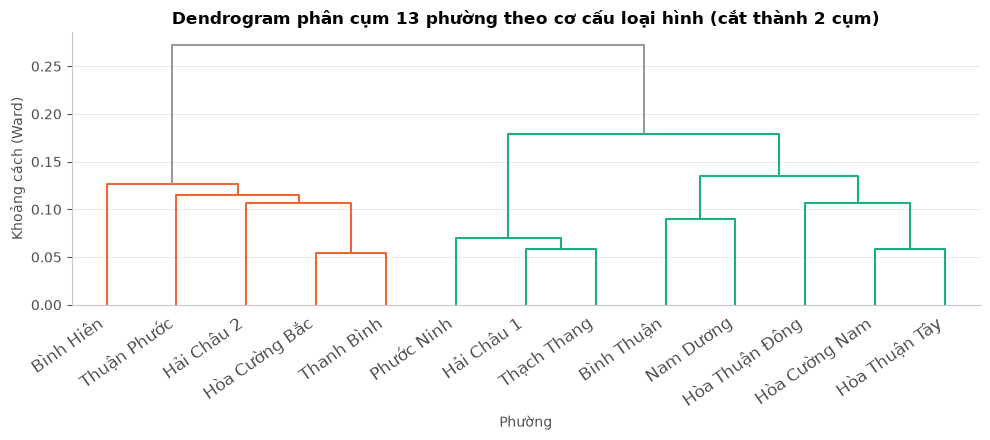

In [14]:
wards = df[df["ward_final"] != "Ngoài Hải Châu"]
W = pd.crosstab(wards["ward_final"], wards["type_group"], normalize="index").reindex(
    columns=ft.GROUP_ORDER + [ft.OTHER_GROUP], fill_value=0)
Z = linkage(W.to_numpy(), method="ward")
sil = {k: silhouette_score(W, fcluster(Z, k, criterion="maxclust")) for k in range(2, 7)}
print("Silhouette theo số cụm phường:", {k: round(v, 3) for k, v in sil.items()})
K_WARD = max(sil, key=sil.get)
W["ward_cluster"] = fcluster(Z, K_WARD, criterion="maxclust")

fig, ax = plt.subplots(figsize=(10, 4.5))
dendrogram(Z, labels=W.index.tolist(), ax=ax, leaf_rotation=35, color_threshold=Z[-(K_WARD - 1), 2],
           above_threshold_color="#9a9994")
ax.set_title(f"Dendrogram phân cụm 13 phường theo cơ cấu loại hình (cắt thành {K_WARD} cụm)")
ax.set_xlabel("Phường"); ax.set_ylabel("Khoảng cách (Ward)"); ax.grid(axis="x", visible=False)
for t in ax.get_xticklabels():
    t.set_ha("right")
fig.tight_layout(); viz.save_fig(fig, "03_ward_dendrogram"); plt.show()

In [15]:
ward_prof = (W.groupby("ward_cluster").mean() * 100).round(1)
ward_prof.insert(0, "phường", W.groupby("ward_cluster").apply(lambda g: ", ".join(g.index)))
overall = wards["type_group"].value_counts(normalize=True).reindex(ft.GROUP_ORDER + [ft.OTHER_GROUP]) * 100
diff = ward_prof.drop(columns="phường") - overall.values
ward_prof["đặc trưng (lệch so với TB quận, điểm %)"] = diff.apply(
    lambda r: ", ".join(f"{c} {v:+.1f}" for c, v in r.sort_values(key=abs, ascending=False).head(3).items()), axis=1)
ward_prof.to_csv(TABLES / "03_ward_clusters.csv", encoding="utf-8-sig")
ward_prof[["phường", "đặc trưng (lệch so với TB quận, điểm %)"]]

type_group,phường,"đặc trưng (lệch so với TB quận, điểm %)"
ward_cluster,,
1,"Bình Hiên, Hòa Cường Bắc, Hải Châu 2, Thanh Bình, Thuận Phước","Cà phê & nước -6.4, Bún/Phở/Cháo +2.7, Fast food & Quốc tế -1.9"
2,"Bình Thuận, Hòa Cường Nam, Hòa Thuận Tây, Hòa Thuận Đông, Hải Châu 1, Nam Dư...","Cà phê & nước +2.5, Bún/Phở/Cháo -2.2, Fast food & Quốc tế +0.7"


## 7. Xuất kết quả

In [16]:
out = df[["storeId", "km_label", "dbscan_label", "is_hotspot", "hdbscan_label"]].copy()
out["ward_cluster"] = df["ward_final"].map(W["ward_cluster"]).astype("Int64")
out.to_csv(PROC / "stores_clusters.csv", index=False)
print("Đã ghi:", (PROC / "stores_clusters.csv").relative_to(ROOT), out.shape)
print("Đã ghi:", (TABLES / "cluster_profiles.csv").relative_to(ROOT))

Đã ghi: data\processed\stores_clusters.csv (3208, 6)
Đã ghi: outputs\tables\cluster_profiles.csv


## 8. Nhận xét

1. **K-Means (k = 5) chỉ chia quận thành 5 dải Bắc–Nam có kích thước tương đương** (408–790 cửa hàng mỗi cụm). Cách chia này không phân biệt được khu đông đúc với khu thưa, nên không phát hiện được điểm nóng.
2. **DBSCAN với eps 150–300 m bị nối chuỗi.** Một cụm chứa 66–99% cửa hàng, cho thấy mạng lưới F&B ở Hải Châu gần như **liên tục**. Chỉ khi đặt ngưỡng "≥ 25 quán trong 100 m", DBSCAN mới tách ra được **14 hotspot** chứa 51,4% cửa hàng.
3. **Các hotspot lớn nhất:**
   - Hotspot 0 (382 cửa hàng): Hoàng Diệu, Huỳnh Thúc Kháng, Lê Đình Dương.
   - Hotspot 1 (299): Lê Hồng Phong, Trần Quốc Toản, Thái Phiên, thuộc Phước Ninh.
   - Hotspot 2 (198): Phan Đăng Lưu, Lê Thanh Nghị.
   - Hotspot 3 (142): Nguyễn Chí Thanh, Quang Trung, Lê Lợi, thuộc Hải Châu 1.

   Hotspot thường hình thành **dọc theo một vài tuyến phố** chứ không phải hình tròn quanh một tâm. Đây là lý do thuật toán dựa trên mật độ phù hợp hơn K-Means.
4. **Mỗi hotspot có "tính cách" riêng:**
   - Hotspot khu Hải Châu 1 (Nguyễn Chí Thanh) và Hòa Cường Nam (Tố Hữu) nghiêng về **cà phê** (28–31%).
   - Hotspot 8 (Ngô Gia Tự – Trần Kế Xương) có tới 39,7% **Bún/Phở/Cháo**.
   - Hotspot 11 quanh **chợ Cồn** có 42% là cửa hàng thực phẩm.
5. **Nằm trong hotspot không làm rating cao hơn** (4,13 so với 4,11, Mann–Whitney p = 0,12). Cơ cấu loại hình trong và ngoài hotspot chỉ khác nhau nhẹ (p ≈ 0,04): trong hotspot có nhiều Fast food & Quốc tế hơn (8,1% so với 5,6%) và ít Lẩu & Nướng hơn.
6. **HDBSCAN (leaf) cho kết quả chi tiết hơn** (21 cụm nhỏ, 56% nhiễu, Silhouette 0,54) và khớp với DBSCAN ở 73% cửa hàng (hotspot hay không). Hai thuật toán **đồng thuận về vị trí các lõi đông đúc**, chỉ khác ở mức độ chia nhỏ (ARI 0,38).
7. **Phân cụm phường chia 13 phường thành 2 nhóm, nhưng Silhouette chỉ 0,25**, tức cơ cấu loại hình giữa các phường không khác nhau quá mạnh.
   - Nhóm "ít cà phê, nhiều bún/phở" gồm Bình Hiên, Thuận Phước, Hải Châu 2, Hòa Cường Bắc, Thanh Bình.
   - Nhóm còn lại nhiều cà phê hơn. Trong nhóm này, ba phường trung tâm **Phước Ninh, Hải Châu 1, Thạch Thang** gần nhau nhất trên dendrogram.

Hàm ý cho notebook 05: vị trí có ảnh hưởng tới loại hình, nhưng **ảnh hưởng ở mức vừa phải**, nên không nên kỳ vọng mô hình dự đoán loại hình đạt độ chính xác rất cao.